# 03 — Baseline Models

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric sections:** Model / Pipeline Design & Building, Model Training (baselines)

So, before building any neural network, we need to know what "good" looks like. A deep model that can't
beat a simple rule isn't worth its complexity, and a model with nothing to compare against can't be judged
at all. In this notebook, we set up the forecasting pipeline that every model will share, then build four
baselines of increasing sophistication:

1. **No motion:** assume the storm stays where it is.
2. **Persistence:** assume it keeps its last 6-hour motion for another 24 hours.
3. **Linear regression:** a statistical model in the spirit of CLIPER, the classic "climatology and
   persistence" benchmark used in operational verification (Neumann, 1972).
4. **XGBoost:** gradient-boosted trees (Chen & Guestrin, 2016), the strongest non-neural baseline.

That way, the LSTM and GRU in the next notebook have a clear, honest target: beat XGBoost.

| | |
|---|---|
| **Input** | `data/processed/tracks_clean.csv.gz` (from notebook 01) |
| **Shared code** | `src/stormtrack/windows.py`: builds forecast samples and scores forecasts (reused by notebook 04) |
| **Output** | `data/processed/preds_val_baselines.csv`, `models/xgb_*.json`, figures `fig11`–`fig14` |

One important ground rule: every choice in this notebook is made on the **validation** seasons
(2017–2019). The test seasons (2020–2024) stay locked away until the final evaluation, so that the final
comparison is a fair one.

### Setting things up

Along with the usual libraries, here we bring in scikit-learn for the linear model and XGBoost for the
boosted trees. From the project's own code, `windows.py` supplies everything forecast-specific: building
samples, the persistence forecast, and turning a predicted displacement back into a position so its error
can be measured.

Since all of this runs on a laptop that's also used for everyday work, XGBoost is limited to 4 CPU threads, and every random
seed is fixed so that the results can be reproduced exactly.

In [1]:
# Imports and paths
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, persistence_displacement, track_error_km,
                                FEATURE_COLS, TARGET_COLS, MOTION_COLS)

FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
SEED, N_THREADS = 42, 4
NHC_24H_ATL_KM = 63          # NHC official 24-h Atlantic track error, 2020-2024 mean (National Hurricane Center, 2025)

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

## 1. From tracks to forecast samples

Here is how a single forecast is framed. Picture a storm at some moment, the **origin**. The forecaster is
allowed to look back 24 hours, at the origin fix and the 3 fixes before it, and has to say where the storm
will be 24 hours later.

So, in the cell below, `build_samples()` walks along every continuous segment and turns each eligible
origin into one row. The row holds:

| Group | Columns | Why it is there |
|---|---|---|
| Recent motion | `dx_m0, dy_m0` (last 6 h), `dx_m1, dy_m1`, `dx_m2, dy_m2` (earlier steps) | Storms keep moving the way they have been moving (EDA Section 5) |
| Location | `lat`, `sin_lon`, `cos_lon` | Recurvature depends on latitude; longitude as sine/cosine has no jump at the date line |
| Time of year | `sin_doy`, `cos_doy` | Steering patterns shift with the season |
| Intensity | `wind_kt`, `dwind_6h`, `dwind_18h` | Strong storms are steered by deeper layers of the atmosphere |
| Land | `dist2land_km` | Storms near land can slow down or turn |
| **Target** | `dx_target, dy_target` | Displacement over the next 24 h, in km east and north |

All motions and targets are measured in km, in a local east/north frame centred on the origin. Because
features and target share the same frame, a predicted displacement converts back into a latitude and
longitude exactly. As a bonus, storms crossing the date line need no special handling.

In [2]:
tracks = load_clean()
S = build_samples(tracks)

print(f"Forecast samples: {len(S):,}")
print(S.groupby("split").size().reindex(["train", "val", "test"]).to_string())
print("Missing values in features or targets:", int(S[FEATURE_COLS + TARGET_COLS].isna().sum().sum()))
S[["SEG_ID", "ISO_TIME", "BASIN"] + FEATURE_COLS[:6] + ["lat", "wind_kt"] + TARGET_COLS].head()

Forecast samples: 76,613
split
train    65169
val       4699
test      6745
Missing values in features or targets: 0


,SEG_ID,ISO_TIME,BASIN,dx_m0,dy_m0,dx_m1,dy_m1,dx_m2,dy_m2,lat,wind_kt,dx_target,dy_target
0,1980001S13173_1,1980-01-01 18:00:00,SP,21.815462,33.3585,10.907731,44.4780,-10.907731,66.7170,-11.2,30.0,130.892770,-144.5535
1,1980001S13173_1,1980-01-02 00:00:00,SP,32.723193,0.0000,21.815462,33.3585,10.907731,44.4780,-11.2,30.0,152.708232,-200.1510
2,1980001S13173_1,1980-01-02 06:00:00,SP,21.784774,-44.4780,32.677161,0.0000,21.784774,33.3585,-11.6,30.0,163.385805,-255.7485
3,1980001S13173_1,1980-01-02 12:00:00,SP,32.629537,-44.4780,21.753024,-44.4780,32.629537,0.0000,-12.0,35.0,163.147684,-333.5850
4,1980001S13173_1,1980-01-02 18:00:00,SP,43.423694,-55.5975,32.567770,-44.4780,21.711847,-44.4780,-12.5,35.0,151.982928,-411.4215


So we have 76,613 forecast samples, exactly the number the EDA counted, with no missing values anywhere.

It's worth pausing on the very first rows, from Cyclone Peni in the South Pacific in 1980. In the first sample, Peni's last 6-hour step went north (`dy_m0` = +33 km), yet over the next 24 hours it actually moved 145 km *south* (`dy_target`). A storm that reverses like this is exactly the kind of case persistence will get wrong, and exactly what a learned model has a chance to anticipate.

Next, the tree and linear models need the basin as a number. So we add one-hot basin columns (one 0/1
column per basin), then pull out the feature matrix `X` and target matrix `Y` for each split.

Note that only `train` and `val` are prepared here. The test samples are set aside, untouched, for the
final evaluation notebook.

In [3]:
BASINS = sorted(S["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
X_COLS = FEATURE_COLS + [f"basin_{b}" for b in BASINS]

tr, va = S[S["split"] == "train"].reset_index(drop=True), S[S["split"] == "val"].reset_index(drop=True)
X_tr, Y_tr = tr[X_COLS].to_numpy(), tr[TARGET_COLS].to_numpy()
X_va, Y_va = va[X_COLS].to_numpy(), va[TARGET_COLS].to_numpy()
print(f"Features: {len(X_COLS)}   train: {X_tr.shape}   val: {X_va.shape}")

Features: 22   train: (65169, 22)   val: (4699, 22)


To compare models fairly, every one of them is scored the same way. The helper below takes a model's
predicted displacements, turns them back into positions, and measures the great-circle distance to where
the storm actually was, the same measure the NHC uses. It then reports the mean, median and 90th-percentile
error, over all basins and for the North Atlantic alone (the basin the NHC benchmark covers).

In [4]:
results, val_errors = [], {}

def evaluate(name, pred_disp, data=None, store=True):
    data = va if data is None else data
    err = track_error_km(data, pred_disp)
    na = data["BASIN"].eq("NA").to_numpy()
    row = {"model": name, "mean_km": err.mean(), "median_km": np.median(err),
           "p90_km": np.percentile(err, 90), "NA_mean_km": err[na].mean()}
    if store:
        results.append(row)
        val_errors[name] = err
    return row

def show(rows):
    return pd.DataFrame(rows).set_index("model").round(1)

## 2. Baselines 1 and 2: no motion and persistence

Let's start with the two forecasts that need no training at all.

- **No motion** predicts a displacement of zero, so its error is simply how far the storm travelled.
- **Persistence** repeats the last 6-hour motion four times, a straight-line extrapolation.

Both are scored on the validation seasons.

In [5]:
show([evaluate("No motion", np.zeros_like(Y_va)),
      evaluate("Persistence", persistence_displacement(va))])

,mean_km,median_km,p90_km,NA_mean_km
model,,,,
No motion,391.1,371.6,644.5,461.6
Persistence,168.0,139.2,320.3,182.9


Right away, persistence proves its worth. It cuts the mean error from 391 km to 168 km, which is less than half. On the North Atlantic alone it does a little worse, 183 km, since Atlantic storms move faster and recurve more often. The 90th-percentile column is a useful warning, though: one forecast in ten is still off by more than 320 km.

## 3. Baseline 3: linear regression (CLIPER-style)

Persistence uses only the last 6 hours, and always multiplies by exactly 4. A linear regression can do
better on both counts: it can weigh all three recent motions, and adjust them using latitude, season and
intensity. That's essentially the idea behind CLIPER, which for decades was the standard yardstick for
judging whether a hurricane forecast had any real skill.

In the cell below, we fit a ridge regression (linear regression with a small penalty that keeps the
coefficients stable). The features are standardized first, since ridge treats every feature's scale as
meaningful. We try a few penalty strengths (`alpha`) and keep the one with the lowest validation error.

In [6]:
ridge_rows = []
for alpha in [0.1, 1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X_tr, Y_tr)
    row = evaluate(f"Ridge (alpha={alpha})", m.predict(X_va), store=False)
    ridge_rows.append({**row, "alpha": alpha})
ridge_tab = show(ridge_rows)
best_alpha = ridge_tab["mean_km"].idxmin()
ridge_tab

,mean_km,median_km,p90_km,NA_mean_km,alpha
model,,,,,
Ridge (alpha=0.1),158.3,133.0,298.9,166.0,0.1
Ridge (alpha=1),158.3,133.0,298.9,166.0,1.0
Ridge (alpha=10),158.3,133.1,299.0,166.0,10.0
Ridge (alpha=100),158.3,133.1,299.5,166.4,100.0
Ridge (alpha=1000),158.6,133.8,300.5,170.1,1000.0


Interestingly, the penalty strength barely matters. Every `alpha` from 0.1 to 100 gives the same 158.3 km. With 65 thousand training samples and only 22 features, the regression has plenty of data, so there's little overfitting for the penalty to prevent. We keep the best one and refit it as the linear baseline:

In [7]:
best_alpha_value = float(best_alpha.split("=")[1].rstrip(")"))
ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_value)).fit(X_tr, Y_tr)
show([evaluate("Linear regression", ridge.predict(X_va))])

,mean_km,median_km,p90_km,NA_mean_km
model,,,,
Linear regression,158.3,133.0,298.9,166.0


## 4. Baseline 4: XGBoost

Linear regression can only add things up. But the EDA showed that storm motion is nonlinear: a storm at
30° latitude behaves very differently from one at 15°, even with the same recent track. Gradient-boosted
trees can capture those interactions, which makes XGBoost the natural strongest baseline.

Before tuning, there's one design question worth testing. Trees predict by averaging over groups of similar
training examples, so they can't extrapolate in a straight line the way persistence does. That suggests
two ways to frame the target:

- **Direct:** predict the full 24-hour displacement.
- **Residual:** predict only the *correction* to persistence (actual displacement minus persistence), then
  add persistence back. The trees then only need to learn how storms *depart* from a straight line.

In the helper below, we train one XGBoost model for the east–west component and one for the north–south
component. Each one keeps adding trees until the validation error stops improving for 100 rounds (early
stopping), so the number of trees is chosen automatically.

In [8]:
def fit_xgb(X_train, Y_train, X_val, Y_val, max_depth, learning_rate=0.05):
    models = []
    for j in range(Y_train.shape[1]):
        m = xgb.XGBRegressor(n_estimators=3000, learning_rate=learning_rate, max_depth=max_depth,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             tree_method="hist", early_stopping_rounds=100,
                             n_jobs=N_THREADS, random_state=SEED)
        m.fit(X_train, Y_train[:, j], eval_set=[(X_val, Y_val[:, j])], verbose=False)
        models.append(m)
    return models

def predict_xgb(models, X):
    return np.column_stack([m.predict(X) for m in models])

Now for the comparison itself. In the next cell, we try both target framings at three tree depths (4, 6 and
8 levels), which makes six configurations. Deeper trees can capture more complicated interactions, but they
are also more likely to overfit. For each configuration we record the validation error and the number of
trees early stopping settled on. It takes a minute or two.

In [9]:
import time
P_tr, P_va = persistence_displacement(tr), persistence_displacement(va)
targets = {"direct": (Y_tr, Y_va, 0.0), "residual": (Y_tr - P_tr, Y_va - P_va, 1.0)}

grid, fitted = [], {}
for framing, (yt, yv, add_persist) in targets.items():
    for depth in [4, 6, 8]:
        t0 = time.time()
        models = fit_xgb(X_tr, yt, X_va, yv, max_depth=depth)
        pred = predict_xgb(models, X_va) + add_persist * P_va
        row = evaluate(f"XGB {framing}, depth {depth}", pred, store=False)
        grid.append({**row, "trees": [m.best_iteration + 1 for m in models], "secs": round(time.time() - t0)})
        fitted[(framing, depth)] = models
grid_tab = show(grid)
grid_tab

,mean_km,median_km,p90_km,NA_mean_km,trees,secs
model,,,,,,
"XGB direct, depth 4",149.0,125.3,276.6,161.9,"[684, 1460]",2
"XGB direct, depth 6",149.0,127.1,276.8,163.6,"[281, 469]",1
"XGB direct, depth 8",149.2,127.4,277.9,163.2,"[217, 163]",1
"XGB residual, depth 4",149.0,125.5,276.0,162.6,"[675, 1076]",2
"XGB residual, depth 6",148.5,126.4,277.2,163.7,"[365, 478]",1
"XGB residual, depth 8",148.9,127.4,276.9,164.3,"[187, 304]",1


Here's the honest answer to the design question: it hardly matters. All six configurations land within 0.7 km of each other (148.5 to 149.2 km). The residual framing at depth 6 comes out on top by a hair, so that's the one we keep, but the gap is far too small to call one framing better than the other. Early stopping also did its job, settling on a few hundred trees for each component, and each configuration trained in a couple of seconds.

One caveat to keep in mind is that the validation seasons were used both for early stopping and for picking the configuration. That makes XGBoost's validation score very slightly optimistic, which is precisely why the untouched test seasons are kept for the final verdict.

In [10]:
best = grid_tab["mean_km"].idxmin()
best_framing, best_depth = best.split(", ")[0].split(" ")[1], int(best.split("depth ")[1])
xgb_models = fitted[(best_framing, best_depth)]
add = P_va if best_framing == "residual" else 0.0
print(f"Chosen: {best_framing} target, depth {best_depth}")
show([evaluate("XGBoost", predict_xgb(xgb_models, X_va) + add)])

Chosen: residual target, depth 6


,mean_km,median_km,p90_km,NA_mean_km
model,,,,
XGBoost,148.5,126.4,277.2,163.7


## 5. Comparing the baselines

With all four baselines trained, let's put them side by side. In the table below, each row is a model
scored on the validation seasons. The `skill_vs_persistence_%` column shows how much each model cuts the
mean persistence error, the usual way forecasters express "skill".

In [11]:
summary = show(results)
summary["skill_vs_persistence_%"] = (100 * (1 - summary["mean_km"] / summary.loc["Persistence", "mean_km"])).round(1)
summary

,mean_km,median_km,p90_km,NA_mean_km,skill_vs_persistence_%
model,,,,,
No motion,391.1,371.6,644.5,461.6,-132.8
Persistence,168.0,139.2,320.3,182.9,0.0
Linear regression,158.3,133.0,298.9,166.0,5.8
XGBoost,148.5,126.4,277.2,163.7,11.6


Putting it together, each step up in sophistication pays off:

- **Linear regression** cuts the persistence error by 5.8%, to 158 km.
- **XGBoost** cuts it by 11.6%, to 148.5 km.
- **The worst misses shrink the most.** The 90th-percentile error drops from 320 km to 277 km.

On the North Atlantic, both learned models improve on persistence (183 km down to 166 and 164 km), although there XGBoost is only slightly ahead of the linear model.

A difference in averages could still be luck, though, especially with only three validation seasons. To
check, we use a **paired bootstrap over storms**. We repeatedly resample whole storms with replacement
(2,000 times), recompute the difference in mean error between two models each time, and read off a 95%
confidence interval. Resampling whole storms rather than individual forecasts matters, because forecasts
from the same storm are strongly related to each other. If the interval stays clear of zero, the difference
is very unlikely to be chance.

In [12]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=SEED):
    # mean(err_a - err_b), resampling whole storms; returns estimate and 95% interval
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

pairs = [("Persistence", "Linear regression"), ("Persistence", "XGBoost"), ("Linear regression", "XGBoost")]
boot = pd.DataFrame([{"comparison": f"{a} minus {b}",
                      **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"],
                                 paired_bootstrap(val_errors[a], val_errors[b], va["SID"].to_numpy())))}
                     for a, b in pairs]).set_index("comparison").round(1)
print(f"Validation storms: {va['SID'].nunique()}")
boot

Validation storms: 275


,mean_diff_km,ci_low_km,ci_high_km
comparison,,,
Persistence minus Linear regression,9.6,7.1,12.0
Persistence minus XGBoost,19.4,16.0,23.1
Linear regression minus XGBoost,9.8,7.4,12.4


All three intervals stay well clear of zero. XGBoost beats persistence by 19.4 km on average (95% interval 16.0 to 23.1 km) and beats linear regression by 9.8 km (7.4 to 12.4 km). So across 275 validation storms, these gains are real and not an accident of which storms happened to fall in 2017–2019.

Next, Figure 11 pictures the main comparison: mean validation error for each model, over all basins and
for the North Atlantic only, with NHC's official 63 km Atlantic error drawn as a reference line.

saved reports/figures/fig11_baseline_val_errors.png


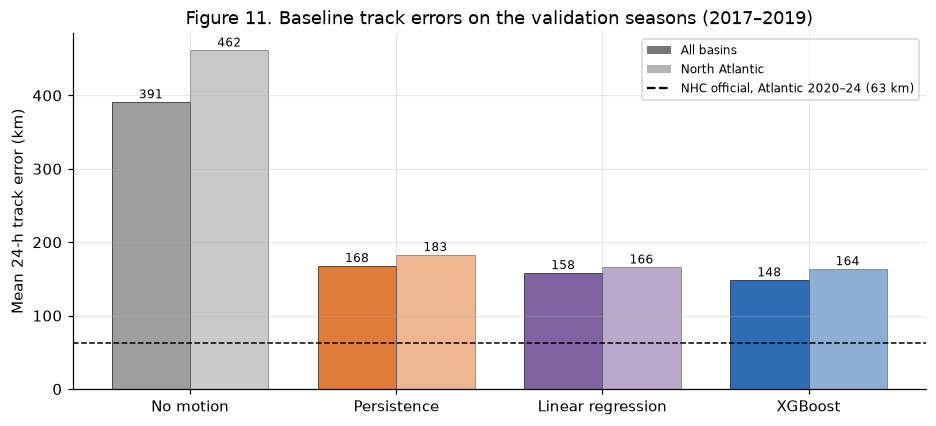

In [13]:
order = ["No motion", "Persistence", "Linear regression", "XGBoost"]
colors = ["#9E9E9E", "#E07B39", "#8064A2", "#2F6DB3"]
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(order)); w = 0.38
for k, (col, lab) in enumerate([("mean_km", "All basins"), ("NA_mean_km", "North Atlantic")]):
    vals = summary.loc[order, col]
    bars = ax.bar(x + (k - 0.5) * w, vals, w, color=colors, alpha=1.0 if k == 0 else 0.55,
                  edgecolor="k", lw=0.4, label=lab)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 5, f"{v:.0f}", ha="center", fontsize=8)
ax.axhline(NHC_24H_ATL_KM, color="k", ls="--", lw=1)
ax.set_xticks(x, order)
ax.set(ylabel="Mean 24-h track error (km)", title="Figure 11. Baseline track errors on the validation seasons (2017–2019)")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(facecolor="#777", label="All basins"), Patch(facecolor="#777", alpha=0.55, label="North Atlantic"),
                   Line2D([], [], color="k", ls="--", label="NHC official, Atlantic 2020–24 (63 km)")], fontsize=8)
savefig(fig, "fig11_baseline_val_errors.png")
plt.show()

## 6. Where does each model gain?

Back in the EDA, we saw that persistence struggles most at higher latitudes, where storms recurve. If the learned
models are capturing real physics, that's where they should help most. So in the cell below, we plot the
mean error of persistence, linear regression and XGBoost in 5° bands of distance from the equator
(Figure 12), along with the number of validation forecasts in each band.

saved reports/figures/fig12_error_by_latitude_baselines.png


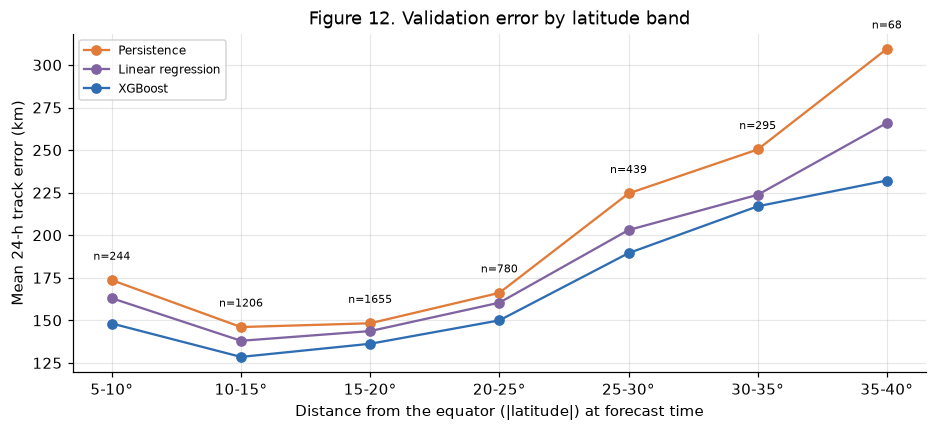

,Persistence,Linear regression,XGBoost
band,,,
5,174.0,163.0,148.0
10,146.0,138.0,129.0
15,148.0,144.0,136.0
20,166.0,160.0,150.0
25,225.0,203.0,189.0
30,250.0,224.0,217.0
35,309.0,266.0,232.0


In [14]:
va["abs_lat_band"] = (va["LAT"].abs() // 5 * 5).astype(int)
band = (pd.DataFrame({m: val_errors[m] for m in order[1:]}).assign(band=va["abs_lat_band"])
          .groupby("band").agg(["mean", "size"]))
band = band[band[("Persistence", "size")] >= 50]
labels = [f"{b}-{b+5}°" for b in band.index]

fig, ax = plt.subplots(figsize=(10, 4))
for m, c in zip(order[1:], colors[1:]):
    ax.plot(labels, band[(m, "mean")], "o-", color=c, label=m)
for i, n in enumerate(band[("Persistence", "size")]):
    ax.text(i, band[("Persistence", "mean")].iloc[i] + 12, f"n={n}", ha="center", fontsize=7)
ax.set(xlabel="Distance from the equator (|latitude|) at forecast time", ylabel="Mean 24-h track error (km)",
       title="Figure 12. Validation error by latitude band")
ax.legend(fontsize=8)
savefig(fig, "fig12_error_by_latitude_baselines.png")
plt.show()
band.xs("mean", axis=1, level=1).round(0)

As hoped, the gains grow exactly where persistence struggles. Below 25° from the equator, XGBoost cuts the persistence error from about 153 km to 137 km (about 10%). From 25° outward, where storms recurve, it cuts it from about 241 km to 203 km (about 16%). In the 35–40° band, it's 309 km down to 232 km, a 25% improvement.

Still, every model's error climbs with latitude, so recurvature remains the hardest part of the problem. These high-latitude forecasts are only 17% of the validation set, but they're where the remaining room for improvement is largest. That makes them the natural place to look for whether a sequence model can do better.

## 7. What did XGBoost learn?

It's also worth opening up the best model to see which inputs it leans on. XGBoost can report the **total gain**
of each feature: how much all the splits on that feature, added together, improved the fit. In the cell
below, we turn that into a share for each of the two models (east–west and north–south), average the two,
and plot the result (Figure 13).

We use *total* gain rather than XGBoost's default *average* gain on purpose. A rarely used 0/1 column, such
as a single basin flag, can post a high average from just a handful of splits, which overstates how much
the model actually depends on it. Either way, gain is a rough guide rather than a precise measure, but it
shows clearly what the model leans on.

saved reports/figures/fig13_xgb_feature_importance.png


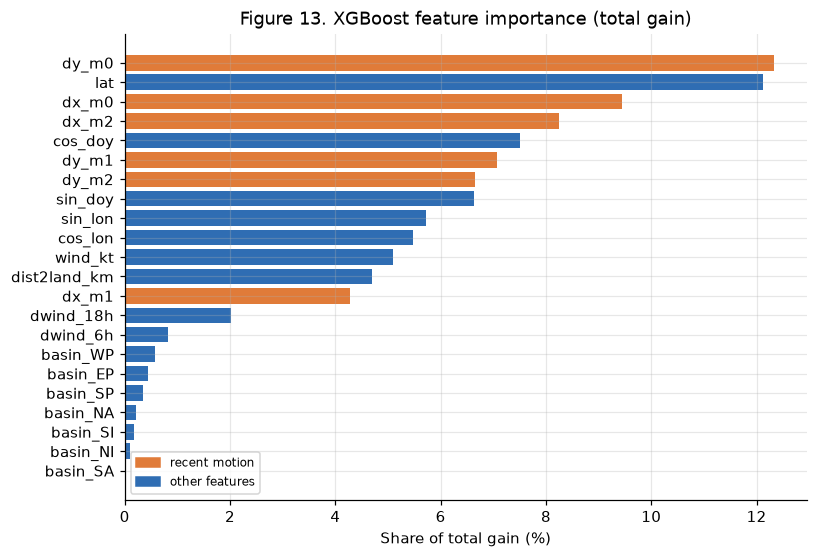

Recent motion features together: 48.0% of total gain
Basin flags together: 1.9%


dy_m0      12.3
lat        12.1
dx_m0       9.5
dx_m2       8.2
cos_doy     7.5
dy_m1       7.1
dy_m2       6.7
sin_doy     6.6
dtype: float64

In [15]:
gain = pd.DataFrame({j: pd.Series(m.get_booster().get_score(importance_type="total_gain"))
                     for j, m in enumerate(xgb_models)}).fillna(0)
gain.index = [X_COLS[int(f[1:])] if f.startswith("f") and f[1:].isdigit() else f for f in gain.index]
gain = (gain / gain.sum()).mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(gain.index, gain.values * 100, color=["#E07B39" if c in MOTION_COLS else "#2F6DB3" for c in gain.index])
ax.set(xlabel="Share of total gain (%)", title="Figure 13. XGBoost feature importance (total gain)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#E07B39", label="recent motion"), Patch(color="#2F6DB3", label="other features")], fontsize=8)
savefig(fig, "fig13_xgb_feature_importance.png")
plt.show()
print(f"Recent motion features together: {gain[MOTION_COLS].sum() * 100:.1f}% of total gain")
print(f"Basin flags together: {gain[[c for c in gain.index if c.startswith('basin_')]].sum() * 100:.1f}%")
(gain.sort_values(ascending=False) * 100).round(1).head(8)

Reassuringly, the model leans on physically sensible inputs:

- **Recent motion** (the six `dx`/`dy` columns) accounts for 48% of the total gain, with the most recent north–south step (`dy_m0`) on top.
- **Latitude** comes a close second as a single feature (12%), which fits the recurvature story from the EDA.
- **Time of year** (`sin_doy`, `cos_doy`) contributes about 14% together, presumably because the large-scale steering winds shift with the seasons.
- **Basin flags** add up to under 2%. Location and season, not the basin label itself, carry the geographic information.

## 8. A storm up close

Averages hide what forecasts actually look like, so finally, let's follow one storm. In the cell below, we
pick the North Atlantic validation segment with the biggest total change of direction, since recurving
storms are the hard case. Then, every 12 hours along its track, we draw where persistence and XGBoost said
it would be 24 hours later, next to where it actually went (Figure 14).

saved reports/figures/fig14_example_storm_forecasts.png


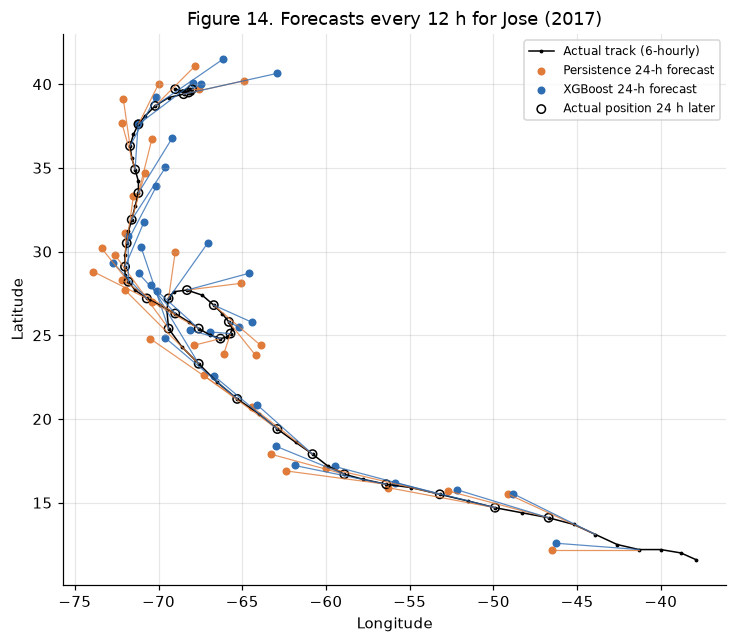

Jose (2017), segment 2017247N09327_1: 32 forecasts shown
Mean error on this storm: persistence 163 km, XGBoost 153 km


In [16]:
va["err_persist"], va["err_xgb"] = val_errors["Persistence"], val_errors["XGBoost"]
pred_xgb = predict_xgb(xgb_models, X_va) + add
from stormtrack.windows import to_latlon
va["lat_px"], va["lon_px"] = to_latlon(va["LAT"], va["LON"], pred_xgb[:, 0], pred_xgb[:, 1])
va["lat_pp"], va["lon_pp"] = to_latlon(va["LAT"], va["LON"], P_va[:, 0], P_va[:, 1])

turning = (tracks[tracks["split"].eq("val") & tracks["BASIN"].eq("NA")]
             .groupby("SEG_ID")["heading_deg"].agg(lambda h: np.abs(((h.diff() + 180) % 360) - 180).sum()))
seg = turning.idxmax()
trk = tracks[tracks["SEG_ID"] == seg]
fc = va[va["SEG_ID"] == seg].iloc[::2]
name, season = trk["NAME"].iloc[0].title(), trk["SEASON"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot(trk["LON"], trk["LAT"], "k.-", lw=1, ms=3, label="Actual track (6-hourly)")
for _, r in fc.iterrows():
    ax.plot([r["LON"], r["lon_pp"]], [r["LAT"], r["lat_pp"]], color="#E07B39", lw=0.8, alpha=0.8)
    ax.plot([r["LON"], r["lon_px"]], [r["LAT"], r["lat_px"]], color="#2F6DB3", lw=0.8, alpha=0.8)
ax.scatter(fc["lon_pp"], fc["lat_pp"], color="#E07B39", s=18, label="Persistence 24-h forecast")
ax.scatter(fc["lon_px"], fc["lat_px"], color="#2F6DB3", s=18, label="XGBoost 24-h forecast")
ax.scatter(fc["lon_true"], fc["lat_true"], facecolor="none", edgecolor="k", s=30, label="Actual position 24 h later")
ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal",
       title=f"Figure 14. Forecasts every 12 h for {name} ({season})")
ax.legend(fontsize=8, loc="best")
savefig(fig, "fig14_example_storm_forecasts.png")
plt.show()
print(f"{name} ({season}), segment {seg}: {len(fc)} forecasts shown")
print(f"Mean error on this storm: persistence {va.loc[va['SEG_ID'] == seg, 'err_persist'].mean():.0f} km, "
      f"XGBoost {va.loc[va['SEG_ID'] == seg, 'err_xgb'].mean():.0f} km")

Hurricane Jose (2017) makes a great test case, because it wandered in a slow loop near 25–30°N for several days. Along its long westward run, both forecasts land close to where Jose actually went. Inside the loop, though, both miss badly: each one projects the storm onward in the direction of its last motion, just as it's about to turn. XGBoost pulls its forecasts back somewhat, so its mean error on this storm is 153 km against 163 km for persistence, but it clearly can't foresee the loop itself.

So it's worth remembering that a better average doesn't mean every forecast is better. Over all validation forecasts, XGBoost beats persistence on about 61% of them.

## 9. Save predictions and models

Last, we save everything later notebooks need. The validation errors of every model go into one table,
so the analysis notebook can compare them with the neural networks forecast by forecast. We also store the
forecast positions of persistence and XGBoost. That way, the neural network notebook can draw them without
loading XGBoost, which is worth avoiding: XGBoost and PyTorch each bring their own copy of a low-level
threading library (OpenMP), and loading both into one Python session can crash it on macOS. The two XGBoost
models are saved too, along with the settings that produced them.

In [17]:
pred_out = va[["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME", "LAT", "LON", "lat_true", "lon_true"]].copy()
for m in order:
    pred_out[f"err_{m.lower().replace(' ', '_')}_km"] = val_errors[m]
# Forecast positions too, so later notebooks can draw them without reloading XGBoost
# (XGBoost and PyTorch ship different OpenMP libraries that can crash one Python process).
pred_out[["pred_lat_persistence", "pred_lon_persistence"]] = va[["lat_pp", "lon_pp"]].to_numpy()
pred_out[["pred_lat_xgboost", "pred_lon_xgboost"]] = va[["lat_px", "lon_px"]].to_numpy()
pred_out.to_csv(PROCESSED / "preds_val_baselines.csv", index=False)

for comp, m in zip(["dx", "dy"], xgb_models):
    m.save_model(MODEL_DIR / f"xgb_{comp}.json")
config = {"framing": best_framing, "max_depth": best_depth, "learning_rate": 0.05,
          "trees": [m.best_iteration + 1 for m in xgb_models], "features": X_COLS, "ridge_alpha": best_alpha_value}
(MODEL_DIR / "xgb_config.json").write_text(pd.Series(config).to_json(indent=2))
print("saved data/processed/preds_val_baselines.csv, models/xgb_dx.json, models/xgb_dy.json, models/xgb_config.json")

saved data/processed/preds_val_baselines.csv, models/xgb_dx.json, models/xgb_dy.json, models/xgb_config.json


## Summary

So, here is where the baselines leave us, all on the validation seasons (2017–2019):

| Model | Mean error | Median | 90th pct | North Atlantic | Skill vs persistence |
|---|---|---|---|---|---|
| No motion | 391 km | 372 km | 645 km | 462 km | −133% |
| Persistence | 168 km | 139 km | 320 km | 183 km | 0% |
| Linear regression (CLIPER-style) | 158 km | 133 km | 299 km | 166 km | 5.8% |
| **XGBoost** (residual target, depth 6) | **148.5 km** | **126 km** | **277 km** | **164 km** | **11.6%** |

A few things stand out for the next step:

- **Learned models add real skill.** XGBoost beats persistence by about 19 km per forecast, and a storm-level bootstrap confirms the gain is not chance.
- **The gains come from recurvature.** Improvements are largest away from the tropics, but those are still the forecasts with the largest errors.
- **Turns are still missed.** Even XGBoost can't anticipate a turn that hasn't started yet, as Hurricane Jose's loop shows.
- **Benchmark gap.** All of these remain well above NHC's 63 km, which is expected for models that see only the storm's own track and none of the surrounding weather.

So the bar for notebook 04 is **148.5 km on the validation seasons**. The LSTM and GRU will receive the same information, but as a sequence of steps rather than a flat row, and the question is whether that structure helps them learn the turns better.

**In production**, this pipeline would run every 6 hours: take the latest four fixes from the operational advisory, build one sample with `build_samples()`, and add the XGBoost correction to the persistence forecast. Scoring takes milliseconds, so it could serve as a fast first guess alongside the full numerical models.

## References

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM
SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794).
https://doi.org/10.1145/2939672.2939785

Gahtan, J., Knapp, K. R., Schreck, C. J., Diamond, H. J., Kossin, J. P., & Kruk, M. C. (2024).
*International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4r01*. NOAA National
Centers for Environmental Information. https://doi.org/10.25921/82ty-9e16

National Hurricane Center. (2025). *Official Atlantic basin annual average track errors, 1989–present*
[Data set]. National Oceanic and Atmospheric Administration.
https://www.nhc.noaa.gov/verification/pdfs/1989-present_OFCL_ATL_annual_trk_errors.pdf

Neumann, C. J. (1972). *An alternate to the HURRAN tropical cyclone forecast system* (NOAA Technical
Memorandum NWS SR-62). National Weather Service.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, É. (2011).
Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*